# Predicting 30-day customer repeat purchase

## Behavioural, cancellation, TF-IDF and MiniLM features

This notebook models one identified customer at each 2011 month end. It uses the UCI Online Retail dataset (ID 352), stored as `data/online+retail.zip`, and compares behavioural features with a conventional TF-IDF benchmark and a frozen MiniLM representation.

The primary question is whether the previous 90 days of merchandise transactions predict a repeat purchase in the following 30 days. The evaluation separates March-June training snapshots, July validation, and August-October rolling test snapshots.

## 0. Environment and configuration

Run `python -m pip install -r requirements.in` before executing this notebook. The source Excel workbook is read directly from the checked-in archive, so no manual extraction or renaming is required.

The notebook stops early if a required package is missing. It does not install packages during analysis.

In [1]:
import importlib
import sys

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "openpyxl": "openpyxl",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sentence_transformers": "sentence-transformers",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
assert not missing, f"Missing packages: {missing}. Run: python -m pip install -r requirements.in"

module_versions = {
    package: getattr(importlib.import_module(module), "__version__", "unknown")
    for module, package in required.items()
}
print("Python:", sys.version.split()[0])
for package, version in module_versions.items():
    print(f"{package}: {version}")

/Users/devoob/Library/Mobile Documents/com~apple~CloudDocs/sem8/ELEC3544 Data Science with Foundation Models/group-project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1105 00:21:16.096000 65424 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python: 3.12.2
numpy: 1.26.4
pandas: 2.2.3
openpyxl: 3.1.5
scikit-learn: 1.8.0
matplotlib: 3.10.0
seaborn: 0.13.2
sentence-transformers: 6.2.0


In [2]:
%matplotlib inline

from pathlib import Path
from zipfile import ZipFile
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, normalize

from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path.cwd()
DATA_ARCHIVE = PROJECT_DIR / "data" / "online+retail.zip"
ARCHIVE_MEMBER = "Online Retail.xlsx"
SHEET_NAME = "Online Retail"
OUTPUT_DIR = PROJECT_DIR / "notebook_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

assert DATA_ARCHIVE.exists(), f"Missing source archive: {DATA_ARCHIVE}"
assert (PROJECT_DIR / "elec3544_proposal.pdf").exists(), "Run the notebook from the project root."

SNAPSHOT_DATES = pd.to_datetime(
    [
        "2011-03-31",
        "2011-04-30",
        "2011-05-31",
        "2011-06-30",
        "2011-07-31",
        "2011-08-31",
        "2011-09-30",
        "2011-10-31",
    ]
)
TRAIN_END = pd.Timestamp("2011-06-30")
VALIDATION_DATE = pd.Timestamp("2011-07-31")
TEST_DATES = pd.to_datetime(["2011-08-31", "2011-09-30", "2011-10-31"])

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
K_CANDIDATES = [8, 12, 16, 20]
K_MATCHED = 16
TFIDF_COMPONENTS = 100
BOOTSTRAP_REPLICATES = 1000

print(f"Source archive: {DATA_ARCHIVE}")
print(f"Output directory: {OUTPUT_DIR}")

Source archive: /Users/devoob/Library/Mobile Documents/com~apple~CloudDocs/sem8/ELEC3544 Data Science with Foundation Models/group-project/data/online+retail.zip
Output directory: /Users/devoob/Library/Mobile Documents/com~apple~CloudDocs/sem8/ELEC3544 Data Science with Foundation Models/group-project/notebook_outputs


## Stage 1. Raw invoice-line data

One row is one product line within an invoice. Repeated invoice numbers are expected because a basket contains several lines.

The downloaded workbook is audited directly. Missing customer IDs and product descriptions are present even though the UCI summary describes the dataset as complete.

In [3]:
with ZipFile(DATA_ARCHIVE) as archive:
    with archive.open(ARCHIVE_MEMBER) as workbook_file:
        raw = pd.read_excel(workbook_file, sheet_name=SHEET_NAME, engine="openpyxl")

raw = raw.rename(
    columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "Customer ID": "CustomerID"}
)
expected_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "CustomerID",
    "Country",
]
assert list(raw.columns) == expected_columns, raw.columns.tolist()
assert len(raw) == 541_909, f"Expected 541,909 rows; found {len(raw):,}"

raw_audit = pd.DataFrame(
    {
        "Metric": [
            "Rows",
            "Columns",
            "First timestamp",
            "Last timestamp",
            "Missing CustomerID",
            "Missing Description",
            "Exact duplicate rows",
            "Unique invoices",
            "Unique stock codes",
        ],
        "Value": [
            len(raw),
            raw.shape[1],
            raw["InvoiceDate"].min(),
            raw["InvoiceDate"].max(),
            raw["CustomerID"].isna().sum(),
            raw["Description"].isna().sum(),
            raw.duplicated().sum(),
            raw["Invoice"].nunique(),
            raw["StockCode"].nunique(),
        ],
    }
)
raw_audit.to_csv(OUTPUT_DIR / "raw_data_audit.csv", index=False)
display(raw.head(10))
display(raw_audit)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


,Metric,Value
0,Rows,541909
1,Columns,8
2,First timestamp,2010-12-01 08:26:00
3,Last timestamp,2011-12-09 12:50:00
4,Missing CustomerID,135080
5,Missing Description,1454
6,Exact duplicate rows,5268
7,Unique invoices,25900
8,Unique stock codes,4070


## Stage 2. Cleaning, transaction classification and product taxonomy

Exact duplicate invoice lines are removed. The sensitivity comparison in this notebook reports their effect on revenue and labels.

The project separates merchandise products from transaction charges. Postage, carriage, manual adjustments, fees, and gift vouchers remain available for revenue auditing but do not enter merchandise features or repeat-purchase labels.

In [4]:
DROP_EXACT_DUPLICATES = True
data = raw.copy()
data["WasExactDuplicate"] = data.duplicated(keep="first")
if DROP_EXACT_DUPLICATES:
    data = data.loc[~data["WasExactDuplicate"]].copy()

data["Invoice"] = data["Invoice"].astype("string").str.strip()
data["StockCode"] = data["StockCode"].astype("string").str.strip()
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")
data["CustomerID"] = pd.to_numeric(data["CustomerID"], errors="coerce").astype("Int64")
data["Quantity"] = pd.to_numeric(data["Quantity"], errors="coerce")
data["Price"] = pd.to_numeric(data["Price"], errors="coerce")

def clean_description(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).upper().strip()
    text = re.sub(r"[^A-Z0-9 ]+", " ", text)
    return re.sub(r"\s+", " ", text).strip() or pd.NA

data["CleanDescription"] = data["Description"].map(clean_description).astype("string")
data["HasCustomerID"] = data["CustomerID"].notna()
data["IsCancellation"] = (
    data["Invoice"].str.upper().str.startswith("C", na=False)
    | data["Quantity"].lt(0)
)
data["IsValidPurchase"] = (
    data["HasCustomerID"]
    & ~data["IsCancellation"]
    & data["Quantity"].gt(0)
    & data["Price"].gt(0)
    & data["InvoiceDate"].notna()
)
data["LineRevenue"] = data["Quantity"] * data["Price"]
data["PurchaseDate"] = data["InvoiceDate"].dt.normalize()

NON_PRODUCT_STOCK_CODES = {
    "POST",
    "DOT",
    "C2",
    "M",
    "m",
    "D",
    "S",
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK",
    "B",
}

def is_non_product_stock(stock_code):
    text = "" if pd.isna(stock_code) else str(stock_code).strip()
    return text in NON_PRODUCT_STOCK_CODES or text.lower().startswith("gift_0001_")

data["IsNonProductLine"] = data["StockCode"].map(is_non_product_stock)

valid_purchase_lines = data.loc[data["IsValidPurchase"]].copy()
charge_lines = valid_purchase_lines.loc[valid_purchase_lines["IsNonProductLine"]].copy()
positive_lines = valid_purchase_lines.loc[
    ~valid_purchase_lines["IsNonProductLine"]
    & valid_purchase_lines["CleanDescription"].notna()
].copy()
return_lines = data.loc[
    data["HasCustomerID"]
    & data["IsCancellation"]
    & ~data["IsNonProductLine"]
].copy()
invalid_or_unidentified = data.loc[
    ~data["IsValidPurchase"]
    & ~(data["HasCustomerID"] & data["IsCancellation"])
].copy()

return_lines["ReturnedValue"] = (
    return_lines["Quantity"].abs() * return_lines["Price"].clip(lower=0)
)
return_lines["ReturnedUnits"] = return_lines["Quantity"].abs()

assert positive_lines["CustomerID"].notna().all()
assert positive_lines["Quantity"].gt(0).all()
assert positive_lines["Price"].gt(0).all()
assert not positive_lines["IsCancellation"].any()
assert not positive_lines["IsNonProductLine"].any()
assert positive_lines["CleanDescription"].notna().all()
assert len(valid_purchase_lines) == len(positive_lines) + len(charge_lines)

cleaning_audit = pd.DataFrame(
    {
        "Stage": [
            "Raw rows",
            "Exact duplicates removed",
            "Cleaned rows",
            "Valid identified purchase lines",
            "Merchandise product lines",
            "Transaction-charge lines",
            "Identified merchandise returns",
            "Other invalid or unidentified lines",
        ],
        "Rows": [
            len(raw),
            int(raw.duplicated().sum()),
            len(data),
            len(valid_purchase_lines),
            len(positive_lines),
            len(charge_lines),
            len(return_lines),
            len(invalid_or_unidentified),
        ],
    }
)
cleaning_audit.to_csv(OUTPUT_DIR / "cleaning_audit.csv", index=False)

non_product_code_audit = (
    data.assign(ExplodedRevenue=data["Quantity"] * data["Price"])
    .groupby(["StockCode", "IsNonProductLine"], dropna=False, as_index=False)
    .agg(
        Rows=("Invoice", "size"),
        Invoices=("Invoice", "nunique"),
        Customers=("CustomerID", "nunique"),
        Revenue=("ExplodedRevenue", "sum"),
        ExampleDescription=(
            "CleanDescription",
            lambda s: s.dropna().iloc[0] if s.notna().any() else "",
        ),
    )
    .rename(columns={"IsNonProductLine": "IsNonProduct"})
)
non_product_code_audit["IncludedInProductFeatures"] = ~non_product_code_audit["IsNonProduct"]
non_product_code_audit.to_csv(OUTPUT_DIR / "non_product_code_audit.csv", index=False)

display(cleaning_audit)
display(non_product_code_audit.query("IsNonProduct").sort_values("Rows", ascending=False))
display(positive_lines.head(10))

,Stage,Rows
0,Raw rows,541909
1,Exact duplicates removed,5268
2,Cleaned rows,536641
3,Valid identified purchase lines,392692
4,Merchandise product lines,391153
5,Transaction-charge lines,1539
6,Identified merchandise returns,8506
7,Other invalid or unidentified lines,135077


,StockCode,IsNonProduct,Rows,Invoices,Customers,Revenue,ExampleDescription,IncludedInProductFeatures
4062,POST,True,1256,1254,379,66230.640,POSTAGE,False
4059,DOT,True,710,710,1,206245.480,DOTCOM POSTAGE,False
4060,M,True,566,517,276,-69034.190,MANUAL,False
4040,C2,True,144,144,29,6986.000,CARRIAGE,False
4042,D,True,77,65,24,-5696.220,DISCOUNT,False
4063,S,True,62,19,0,-3039.650,SAMPLES,False
4039,BANK CHARGES,True,37,36,10,-7175.639,BANK CHARGES,False
4037,AMAZONFEE,True,34,34,0,-221520.500,AMAZON FEE,False
4041,CRUK,True,16,16,1,-7933.430,CRUK COMMISSION,False
4065,gift_0001_20,True,10,10,0,167.050,DOTCOMGIFTSHOP GIFT VOUCHER 20 00,False


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,WasExactDuplicate,CleanDescription,HasCustomerID,IsCancellation,IsValidPurchase,LineRevenue,PurchaseDate,IsNonProductLine
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,WHITE HANGING HEART T LIGHT HOLDER,True,False,True,15.30,2010-12-01,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,WHITE METAL LANTERN,True,False,True,20.34,2010-12-01,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,CREAM CUPID HEARTS COAT HANGER,True,False,True,22.00,2010-12-01,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,KNITTED UNION FLAG HOT WATER BOTTLE,True,False,True,20.34,2010-12-01,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,RED WOOLLY HOTTIE WHITE HEART,True,False,True,20.34,2010-12-01,False
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,False,SET 7 BABUSHKA NESTING BOXES,True,False,True,15.30,2010-12-01,False
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,False,GLASS STAR FROSTED T LIGHT HOLDER,True,False,True,25.50,2010-12-01,False
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,False,HAND WARMER UNION JACK,True,False,True,11.10,2010-12-01,False
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,False,HAND WARMER RED POLKA DOT,True,False,True,11.10,2010-12-01,False
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,False,ASSORTED COLOUR BIRD ORNAMENT,True,False,True,54.08,2010-12-01,False


## Stage 1B. Exploratory data analysis

The EDA records missingness, valid activity over time, revenue concentration, country concentration, target prevalence, and feature skew. These checks justify the cleaning scope, log transforms, class weighting, and chronological evaluation.

In [5]:
eda_data_quality = pd.DataFrame(
    [
        {"Check": "Raw invoice lines", "Rows": len(raw), "ShareOfRaw": 1.0},
        {
            "Check": "Exact duplicate rows",
            "Rows": int(raw.duplicated().sum()),
            "ShareOfRaw": raw.duplicated().mean(),
        },
        {
            "Check": "Missing CustomerID",
            "Rows": int(raw["CustomerID"].isna().sum()),
            "ShareOfRaw": raw["CustomerID"].isna().mean(),
        },
        {
            "Check": "Missing Description",
            "Rows": int(raw["Description"].isna().sum()),
            "ShareOfRaw": raw["Description"].isna().mean(),
        },
        {
            "Check": "Cancellation or negative quantity",
            "Rows": int(data["IsCancellation"].sum()),
            "ShareOfRaw": data["IsCancellation"].mean(),
        },
        {
            "Check": "Non-positive quantity",
            "Rows": int(data["Quantity"].le(0).sum()),
            "ShareOfRaw": data["Quantity"].le(0).mean(),
        },
        {
            "Check": "Non-positive price",
            "Rows": int(data["Price"].le(0).sum()),
            "ShareOfRaw": data["Price"].le(0).mean(),
        },
        {
            "Check": "Valid identified purchase lines",
            "Rows": len(valid_purchase_lines),
            "ShareOfRaw": len(valid_purchase_lines) / len(raw),
        },
        {
            "Check": "Merchandise product lines",
            "Rows": len(positive_lines),
            "ShareOfRaw": len(positive_lines) / len(raw),
        },
    ]
)
eda_data_quality.to_csv(OUTPUT_DIR / "eda_data_quality.csv", index=False)
display(eda_data_quality.style.format({"ShareOfRaw": "{:.2%}"}))

monthly_eda = (
    valid_purchase_lines.assign(
        Month=valid_purchase_lines["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)
    .agg(
        ValidLines=("Invoice", "size"),
        Revenue=("LineRevenue", "sum"),
        EligibleCustomers=("CustomerID", "nunique"),
        Invoices=("Invoice", "nunique"),
    )
)
monthly_eda.to_csv(OUTPUT_DIR / "eda_monthly_activity.csv", index=False)
display(monthly_eda.style.format({"Revenue": "{:,.0f}"}))

,Check,Rows,ShareOfRaw
0,Raw invoice lines,541909,100.00%
1,Exact duplicate rows,5268,0.97%
2,Missing CustomerID,135080,24.93%
3,Missing Description,1454,0.27%
4,Cancellation or negative quantity,10587,1.97%
5,Non-positive quantity,10587,1.97%
6,Non-positive price,2512,0.47%
7,Valid identified purchase lines,392692,72.46%
8,Merchandise product lines,391153,72.18%


,Month,ValidLines,Revenue,EligibleCustomers,Invoices
0,2010-12,25670,"570,423",885,1400
1,2011-01,20988,"568,101",741,987
2,2011-02,19706,"446,085",758,997
3,2011-03,26870,"594,082",974,1321
4,2011-04,22433,"468,374",856,1149
5,2011-05,28073,"677,355",1056,1555
6,2011-06,26926,"660,046",991,1393
7,2011-07,26580,"598,963",949,1331
8,2011-08,26790,"644,051",935,1280
9,2011-09,39669,"950,690",1266,1755


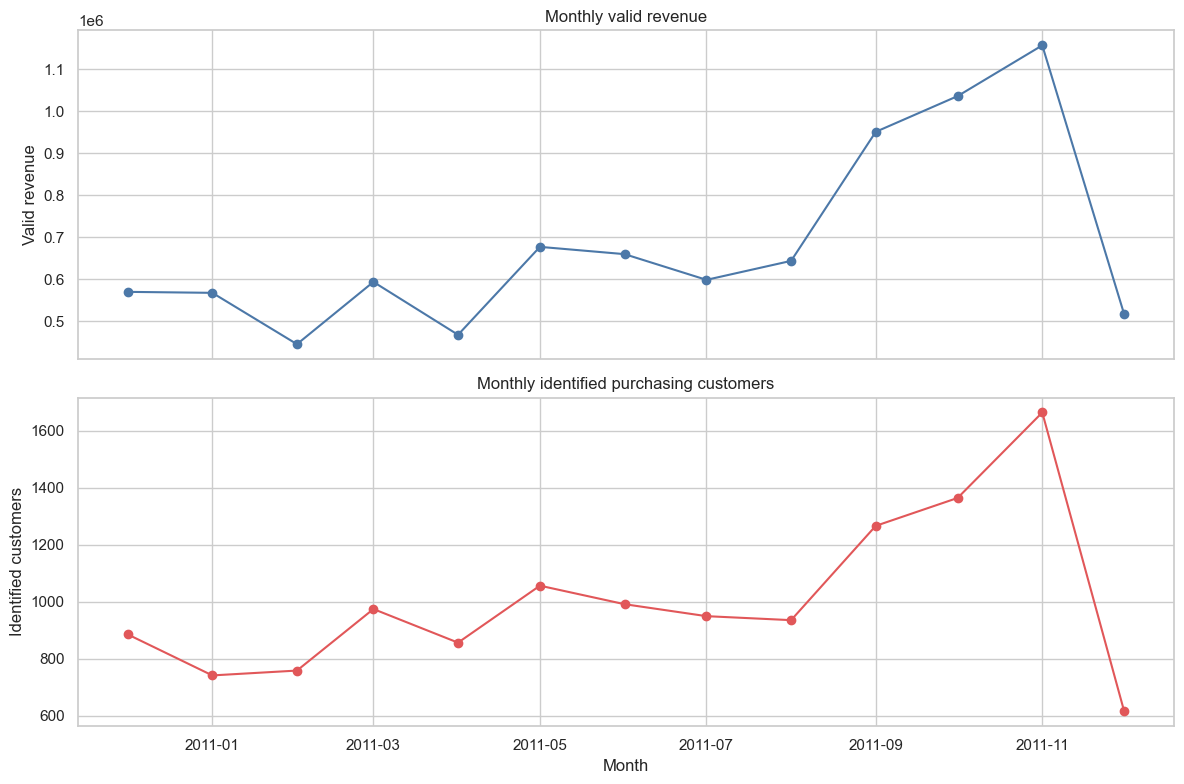

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
monthly_plot = monthly_eda.assign(
    MonthDate=pd.to_datetime(monthly_eda["Month"] + "-01")
)
axes[0].plot(monthly_plot["MonthDate"], monthly_plot["Revenue"], marker="o", color="#4C78A8")
axes[0].set_ylabel("Valid revenue")
axes[0].set_title("Monthly valid revenue")
axes[1].plot(
    monthly_plot["MonthDate"],
    monthly_plot["EligibleCustomers"],
    marker="o",
    color="#E15759",
)
axes[1].set_ylabel("Identified customers")
axes[1].set_xlabel("Month")
axes[1].set_title("Monthly identified purchasing customers")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_raw_activity.png", dpi=180, bbox_inches="tight")
plt.show()

In [7]:
customer_spend = (
    valid_purchase_lines.groupby("CustomerID", as_index=False)["LineRevenue"]
    .sum()
    .sort_values("LineRevenue", ascending=False)
    .reset_index(drop=True)
)
customer_spend["CumulativeRevenueShare"] = (
    customer_spend["LineRevenue"].cumsum() / customer_spend["LineRevenue"].sum()
)
customer_spend["CustomerShare"] = (customer_spend.index + 1) / len(customer_spend)

concentration_rows = []
for share in [0.01, 0.05, 0.10, 0.20]:
    n_customers = max(1, int(np.ceil(len(customer_spend) * share)))
    concentration_rows.append(
        {
            "TopCustomerShare": share,
            "CustomerCount": n_customers,
            "RevenueShare": (
                customer_spend.iloc[:n_customers]["LineRevenue"].sum()
                / customer_spend["LineRevenue"].sum()
            ),
        }
    )
eda_customer_concentration = pd.DataFrame(concentration_rows)
eda_customer_concentration.to_csv(
    OUTPUT_DIR / "eda_customer_concentration.csv", index=False
)
display(
    eda_customer_concentration.style.format(
        {"TopCustomerShare": "{:.0%}", "RevenueShare": "{:.1%}"}
    )
)

country_eda = (
    valid_purchase_lines.groupby("Country", as_index=False)
    .agg(
        ValidLines=("Invoice", "size"),
        Customers=("CustomerID", "nunique"),
        Revenue=("LineRevenue", "sum"),
    )
    .sort_values("Revenue", ascending=False)
)
country_eda["RevenueShare"] = country_eda["Revenue"] / country_eda["Revenue"].sum()
country_eda.to_csv(OUTPUT_DIR / "eda_country_activity.csv", index=False)
display(country_eda.head(15).style.format({"Revenue": "{:,.0f}", "RevenueShare": "{:.1%}"}))

,TopCustomerShare,CustomerCount,RevenueShare
0,1%,44,32.1%
1,5%,217,50.5%
2,10%,434,61.5%
3,20%,868,74.7%


,Country,ValidLines,Customers,Revenue,RevenueShare
35,United Kingdom,349203,3920,"7,285,025",82.0%
23,Netherlands,2359,9,"285,446",3.2%
10,EIRE,7226,3,"265,262",3.0%
14,Germany,9025,94,"228,678",2.6%
13,France,8326,87,"208,934",2.4%
0,Australia,1181,9,"138,454",1.6%
30,Spain,2479,30,"61,559",0.7%
32,Switzerland,1841,21,"56,444",0.6%
3,Belgium,2031,25,"41,196",0.5%
31,Sweden,450,8,"38,368",0.4%


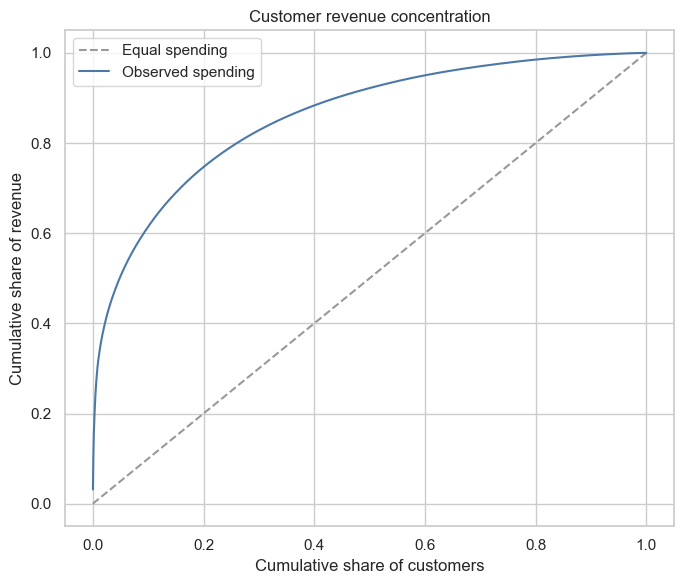

The United Kingdom contributes 82.0% of valid identified revenue.
The top 1% of customers contribute 32.1% of revenue; the top 20% contribute 74.7%.


In [8]:
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle="--", color="#999999", label="Equal spending")
plt.plot(
    customer_spend["CustomerShare"],
    customer_spend["CumulativeRevenueShare"],
    color="#4C78A8",
    label="Observed spending",
)
plt.xlabel("Cumulative share of customers")
plt.ylabel("Cumulative share of revenue")
plt.title("Customer revenue concentration")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "eda_customer_concentration.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print(
    f"The United Kingdom contributes {country_eda.iloc[0]['RevenueShare']:.1%} "
    "of valid identified revenue."
)
print(
    f"The top 1% of customers contribute "
    f"{eda_customer_concentration.iloc[0]['RevenueShare']:.1%} of revenue; "
    f"the top 20% contribute "
    f"{eda_customer_concentration.iloc[-1]['RevenueShare']:.1%}."
)

## Stage 3. Invoice-level merchandise data

Merchandise product lines are aggregated by customer, invoice, and timestamp. Basket and timing features use this table. Charge lines stay outside the modelling table and appear only in the revenue audit.

In [9]:
invoice_summary = (
    positive_lines.groupby(["CustomerID", "Invoice", "InvoiceDate"], observed=True)
    .agg(
        BasketValue=("LineRevenue", "sum"),
        TotalUnits=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        Country=(
            "Country",
            lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0],
        ),
    )
    .reset_index()
)
invoice_summary["PurchaseDate"] = invoice_summary["InvoiceDate"].dt.normalize()
invoice_summary["IsWeekend"] = invoice_summary["InvoiceDate"].dt.dayofweek.ge(5).astype(int)

invoice_audit = pd.DataFrame(
    {
        "Scope": ["Product lines", "Charge lines", "All valid identified lines"],
        "Lines": [len(positive_lines), len(charge_lines), len(valid_purchase_lines)],
        "Revenue": [
            positive_lines["LineRevenue"].sum(),
            charge_lines["LineRevenue"].sum(),
            valid_purchase_lines["LineRevenue"].sum(),
        ],
    }
)
assert np.isclose(
    valid_purchase_lines["LineRevenue"].sum(),
    positive_lines["LineRevenue"].sum() + charge_lines["LineRevenue"].sum(),
)
assert np.isclose(
    positive_lines["LineRevenue"].sum(),
    invoice_summary["BasketValue"].sum(),
)
invoice_audit.to_csv(OUTPUT_DIR / "invoice_revenue_audit.csv", index=False)
display(invoice_summary.head(10))
display(invoice_audit.style.format({"Revenue": "{:,.2f}"}))

,CustomerID,Invoice,InvoiceDate,BasketValue,TotalUnits,UniqueProducts,Country,PurchaseDate,IsWeekend
0,12346,541431,2011-01-18 10:01:00,77183.60,74215,1,United Kingdom,2011-01-18,0
1,12347,537626,2010-12-07 14:57:00,711.79,319,31,Iceland,2010-12-07,0
2,12347,542237,2011-01-26 14:30:00,475.39,315,29,Iceland,2011-01-26,0
3,12347,549222,2011-04-07 10:43:00,636.25,483,24,Iceland,2011-04-07,0
4,12347,556201,2011-06-09 13:01:00,382.52,196,18,Iceland,2011-06-09,0
5,12347,562032,2011-08-02 08:48:00,584.91,277,22,Iceland,2011-08-02,0
6,12347,573511,2011-10-31 12:25:00,1294.32,676,47,Iceland,2011-10-31,0
7,12347,581180,2011-12-07 15:52:00,224.82,192,11,Iceland,2011-12-07,0
8,12348,539318,2010-12-16 19:09:00,652.80,1248,12,Finland,2010-12-16,0
9,12348,541998,2011-01-25 10:42:00,187.44,600,5,Finland,2011-01-25,0


,Scope,Lines,Revenue
0,Product lines,391153,"8,737,227.64"
1,Charge lines,1539,"149,981.25"
2,All valid identified lines,392692,"8,887,208.89"


## Stages 4-7. Customer snapshots, RFM, behaviour and cancellations

For snapshot date `t`, features use the 90 days ending after the full snapshot day. Labels use the next 30 days. A customer enters a snapshot only after at least one merchandise purchase in the feature window.

Each customer-snapshot row has a unique `SnapshotDate` and `CustomerID` pair. Target transactions never enter the feature calculations.

,SnapshotDate,EligibleCustomers,RepeatCustomers,RepeatPurchaseRate
0,2011-03-31 00:00:00,1774,492,27.7%
1,2011-04-30 00:00:00,1889,669,35.4%
2,2011-05-31 00:00:00,1957,634,32.4%
3,2011-06-30 00:00:00,1966,616,31.3%
4,2011-07-31 00:00:00,2019,641,31.7%
5,2011-08-31 00:00:00,1919,723,37.7%
6,2011-09-30 00:00:00,2145,755,35.2%
7,2011-10-31 00:00:00,2454,1052,42.9%


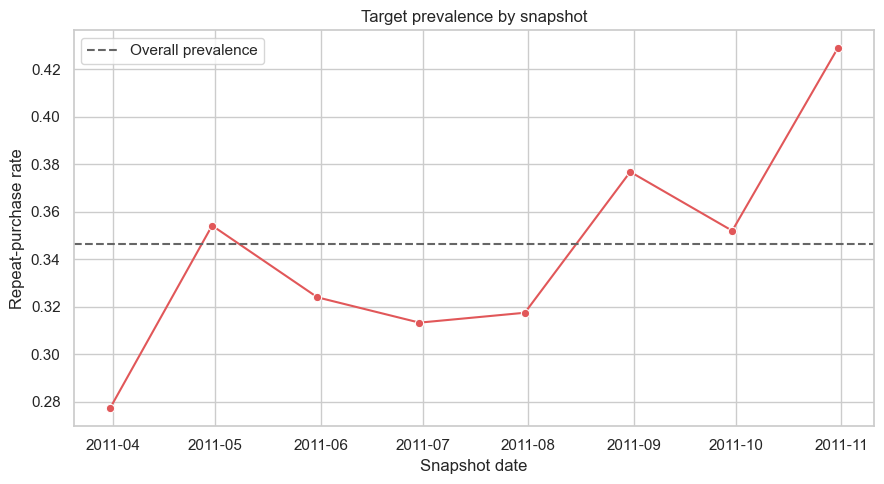

Target prevalence changes from 27.7% in March to 42.9% in October. PR-AUC is therefore reported alongside each month's positive prevalence.


In [10]:
def gap_statistics(invoice_dates):
    dates = np.sort(
        pd.Series(invoice_dates).drop_duplicates().values.astype("datetime64[ns]")
    )
    if len(dates) < 2:
        return np.nan, np.nan
    gaps = np.diff(dates) / np.timedelta64(1, "D")
    return float(np.mean(gaps)), float(np.std(gaps, ddof=1)) if len(gaps) > 1 else 0.0

def build_base_snapshot(snapshot_date):
    snapshot_date = pd.Timestamp(snapshot_date).normalize()
    feature_end = snapshot_date + pd.Timedelta(days=1)
    feature_start = feature_end - pd.Timedelta(days=90)
    target_start = feature_end
    target_end = target_start + pd.Timedelta(days=30)

    hist_lines = positive_lines.loc[
        positive_lines["InvoiceDate"].ge(feature_start)
        & positive_lines["InvoiceDate"].lt(feature_end)
    ].copy()
    hist_invoices = invoice_summary.loc[
        invoice_summary["InvoiceDate"].ge(feature_start)
        & invoice_summary["InvoiceDate"].lt(feature_end)
    ].copy()
    future = positive_lines.loc[
        positive_lines["InvoiceDate"].ge(target_start)
        & positive_lines["InvoiceDate"].lt(target_end)
    ]
    hist_returns = return_lines.loc[
        return_lines["InvoiceDate"].ge(feature_start)
        & return_lines["InvoiceDate"].lt(feature_end)
    ].copy()

    snap = (
        hist_lines.groupby("CustomerID", observed=True)
        .agg(
            LastPurchase=("InvoiceDate", "max"),
            FirstPurchaseInWindow=("InvoiceDate", "min"),
            Frequency90D=("Invoice", "nunique"),
            Monetary90D=("LineRevenue", "sum"),
            TotalUnits90D=("Quantity", "sum"),
            UniqueProducts90D=("StockCode", "nunique"),
            ActivePurchaseDays=("PurchaseDate", "nunique"),
            UKLineShare=("Country", lambda s: s.eq("United Kingdom").mean()),
        )
        .reset_index()
    )
    snap["RecencyDays"] = (feature_end - snap["LastPurchase"]).dt.total_seconds() / 86400
    snap["HistorySpanDays90D"] = (
        feature_end - snap["FirstPurchaseInWindow"]
    ).dt.total_seconds() / 86400
    snap["IsUK"] = snap["UKLineShare"].ge(0.5).astype(int)

    basket = (
        hist_invoices.groupby("CustomerID", observed=True)
        .agg(
            AverageBasketValue=("BasketValue", "mean"),
            MaximumBasketValue=("BasketValue", "max"),
            WeekendInvoiceShare=("IsWeekend", "mean"),
        )
        .reset_index()
    )
    last30 = (
        hist_invoices.loc[
            hist_invoices["InvoiceDate"].ge(feature_end - pd.Timedelta(days=30))
        ]
        .groupby("CustomerID", observed=True)["Invoice"]
        .nunique()
        .rename("InvoicesLast30D")
        .reset_index()
    )
    gap_rows = [
        (customer_id, *gap_statistics(group["InvoiceDate"]))
        for customer_id, group in hist_invoices.groupby(
            "CustomerID", observed=True, sort=False
        )
    ]
    gaps = pd.DataFrame(
        gap_rows, columns=["CustomerID", "MeanGapDays", "GapStdDays"]
    )

    snap = (
        snap.merge(basket, on="CustomerID", how="left")
        .merge(last30, on="CustomerID", how="left")
        .merge(gaps, on="CustomerID", how="left")
    )
    snap["InvoicesLast30D"] = snap["InvoicesLast30D"].fillna(0).astype(int)
    snap["HasMultipleInvoices"] = snap["Frequency90D"].ge(2).astype(int)

    if len(hist_returns):
        cancel = (
            hist_returns.groupby("CustomerID", observed=True)
            .agg(
                CancellationLines=("Invoice", "size"),
                CancellationInvoices=("Invoice", "nunique"),
                ReturnedValue90D=("ReturnedValue", "sum"),
                ReturnedUnits90D=("ReturnedUnits", "sum"),
                LastCancellation=("InvoiceDate", "max"),
            )
            .reset_index()
        )
        snap = snap.merge(cancel, on="CustomerID", how="left")
    else:
        for column in [
            "CancellationLines",
            "CancellationInvoices",
            "ReturnedValue90D",
            "ReturnedUnits90D",
        ]:
            snap[column] = 0
        snap["LastCancellation"] = pd.NaT

    zero_columns = [
        "CancellationLines",
        "CancellationInvoices",
        "ReturnedValue90D",
        "ReturnedUnits90D",
    ]
    snap[zero_columns] = snap[zero_columns].fillna(0)
    snap["HasCancellation"] = snap["CancellationInvoices"].gt(0).astype(int)
    snap["CancellationRate"] = (
        snap["CancellationInvoices"]
        / (snap["Frequency90D"] + snap["CancellationInvoices"]).replace(0, np.nan)
    ).fillna(0)
    snap["DaysSinceLastCancellation"] = (
        feature_end - snap["LastCancellation"]
    ).dt.total_seconds() / 86400

    positive_future_customers = set(future["CustomerID"].dropna().astype(int))
    snap["RepeatPurchase30D"] = (
        snap["CustomerID"].astype(int).isin(positive_future_customers).astype(int)
    )
    snap["SnapshotDate"] = snapshot_date
    snap["FeatureStart"] = feature_start
    snap["FeatureEndExclusive"] = feature_end
    snap["TargetStart"] = target_start
    snap["TargetEndExclusive"] = target_end
    return snap

base_snapshots = pd.concat(
    [build_base_snapshot(snapshot_date) for snapshot_date in SNAPSHOT_DATES],
    ignore_index=True,
)
assert not base_snapshots.duplicated(["SnapshotDate", "CustomerID"]).any()
assert base_snapshots["FeatureEndExclusive"].eq(base_snapshots["TargetStart"]).all()
assert (
    base_snapshots["FeatureEndExclusive"] - base_snapshots["FeatureStart"]
).dt.days.eq(90).all()
assert (
    base_snapshots["TargetEndExclusive"] - base_snapshots["TargetStart"]
).dt.days.eq(30).all()
assert base_snapshots["TargetEndExclusive"].max() <= raw["InvoiceDate"].max()

snapshot_audit = (
    base_snapshots.groupby("SnapshotDate")
    .agg(
        EligibleCustomers=("CustomerID", "size"),
        RepeatCustomers=("RepeatPurchase30D", "sum"),
        RepeatPurchaseRate=("RepeatPurchase30D", "mean"),
    )
    .reset_index()
)
snapshot_audit.to_csv(OUTPUT_DIR / "eda_snapshot_balance.csv", index=False)
display(snapshot_audit.style.format({"RepeatPurchaseRate": "{:.1%}"}))

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=snapshot_audit,
    x="SnapshotDate",
    y="RepeatPurchaseRate",
    marker="o",
    color="#E15759",
)
plt.axhline(
    base_snapshots["RepeatPurchase30D"].mean(),
    linestyle="--",
    color="#666666",
    label="Overall prevalence",
)
plt.ylabel("Repeat-purchase rate")
plt.xlabel("Snapshot date")
plt.title("Target prevalence by snapshot")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_snapshot_balance.png", dpi=180, bbox_inches="tight")
plt.show()

print(
    f"Target prevalence changes from "
    f"{snapshot_audit['RepeatPurchaseRate'].iloc[0]:.1%} in March to "
    f"{snapshot_audit['RepeatPurchaseRate'].iloc[-1]:.1%} in October. "
    "PR-AUC is therefore reported alongside each month's positive prevalence."
)

In [11]:
customer_example = base_snapshots.loc[
    base_snapshots["CustomerID"].eq(13047),
    [
        "SnapshotDate",
        "CustomerID",
        "RecencyDays",
        "Frequency90D",
        "Monetary90D",
        "TotalUnits90D",
        "UniqueProducts90D",
        "AverageBasketValue",
        "ActivePurchaseDays",
        "CancellationRate",
        "RepeatPurchase30D",
    ],
].copy()
display(customer_example.round(2))

,SnapshotDate,CustomerID,RecencyDays,Frequency90D,Monetary90D,TotalUnits90D,UniqueProducts90D,AverageBasketValue,ActivePurchaseDays,CancellationRate,RepeatPurchase30D
237,2011-03-31,13047,1.44,2,886.05,404,37,443.02,2,0.50,0
2001,2011-04-30,13047,31.44,2,886.05,404,37,443.02,2,0.33,1
3894,2011-05-31,13047,27.41,2,846.15,369,36,423.08,2,0.33,1
5858,2011-06-30,13047,11.42,2,981.40,350,44,490.70,2,0.33,0
7836,2011-07-31,13047,42.42,2,981.40,350,44,490.70,2,0.50,1
9857,2011-08-31,13047,27.25,2,1010.33,483,47,505.16,2,0.67,0
11809,2011-09-30,13047,57.25,1,447.93,309,26,447.93,1,0.75,1
13972,2011-10-31,13047,17.53,2,998.51,535,53,499.26,2,0.60,0


## Stage 8. Product text representations

TF-IDF is the conventional text baseline. Raw sparse TF-IDF is reduced with 100-component truncated singular value decomposition before KMeans, because KMeans over 8,000 sparse columns produces one dominant cluster in this dataset.

MiniLM is the frozen pretrained `all-MiniLM-L6-v2` encoder. Both representations learn cluster centres only from descriptions observed through June 2011. K=16 is also evaluated for both representations as a matched-cluster sensitivity check.

In [12]:
description_table = (
    positive_lines.loc[positive_lines["CleanDescription"].notna(), ["CleanDescription"]]
    .drop_duplicates()
    .sort_values("CleanDescription")
    .reset_index(drop=True)
)
train_descriptions = set(
    positive_lines.loc[
        positive_lines["InvoiceDate"].lt("2011-07-01")
        & positive_lines["CleanDescription"].notna(),
        "CleanDescription",
    ].unique()
)
description_table["SeenByTrainingEnd"] = description_table["CleanDescription"].isin(
    train_descriptions
)
all_descriptions = description_table["CleanDescription"].tolist()
train_mask = description_table["SeenByTrainingEnd"].to_numpy()
descriptions_seen_through_june = int(train_mask.sum())

print(f"Unique merchandise descriptions: {len(description_table):,}")
print(f"Descriptions seen through June: {descriptions_seen_through_june:,}")
assert descriptions_seen_through_june == len(train_descriptions)
display(description_table.head(10))

Unique merchandise descriptions: 3,836
Descriptions seen through June: 3,332


,CleanDescription,SeenByTrainingEnd
0,10 COLOUR SPACEBOY PEN,True
1,12 COLOURED PARTY BALLOONS,True
2,12 DAISY PEGS IN WOOD BOX,True
3,12 EGG HOUSE PAINTED WOOD,True
4,12 HANGING EGGS HAND PAINTED,False
5,12 IVORY ROSE PEG PLACE SETTINGS,True
6,12 MESSAGE CARDS WITH ENVELOPES,True
7,12 PENCIL SMALL TUBE WOODLAND,True
8,12 PENCILS SMALL TUBE RED RETROSPOT,True
9,12 PENCILS SMALL TUBE SKULL,True


In [13]:
def fit_fixed_k(X_train, k, random_state=RANDOM_STATE):
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=20,
        batch_size=512,
        reassignment_ratio=0.01,
    )
    model.fit(X_train)
    return model

def choose_cluster_count(X_train, candidates, representation_name):
    rows = []
    models = {}
    rng = np.random.default_rng(RANDOM_STATE)
    sample_size = min(2000, X_train.shape[0])
    sample_idx = rng.choice(X_train.shape[0], size=sample_size, replace=False)
    for k in candidates:
        model = fit_fixed_k(X_train, k)
        labels = model.labels_
        silhouette = silhouette_score(
            X_train[sample_idx], labels[sample_idx], metric="cosine"
        )
        counts = np.bincount(labels, minlength=k)
        rows.append(
            {
                "Representation": representation_name,
                "K": k,
                "SilhouetteCosine": silhouette,
                "SmallestCluster": int(counts.min()),
                "LargestCluster": int(counts.max()),
                "LargestClusterShare": float(counts.max() / len(labels)),
            }
        )
        models[k] = model
    results = pd.DataFrame(rows).sort_values("SilhouetteCosine", ascending=False)
    best_k = int(results.iloc[0]["K"])
    return results, models[best_k]

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True,
    max_features=8000,
)
X_tfidf_train_sparse = tfidf_vectorizer.fit_transform(
    description_table.loc[train_mask, "CleanDescription"]
)
X_tfidf_all_sparse = tfidf_vectorizer.transform(description_table["CleanDescription"])
tfidf_svd = TruncatedSVD(
    n_components=min(TFIDF_COMPONENTS, X_tfidf_train_sparse.shape[0] - 1),
    random_state=RANDOM_STATE,
)
X_tfidf_train = normalize(tfidf_svd.fit_transform(X_tfidf_train_sparse))
X_tfidf_all = normalize(tfidf_svd.transform(X_tfidf_all_sparse))

tfidf_k_results, tfidf_clusterer = choose_cluster_count(
    X_tfidf_train, K_CANDIDATES, "TF-IDF + LSA"
)
description_table["TFIDFBestCluster"] = tfidf_clusterer.predict(X_tfidf_all)
display(tfidf_k_results)

tfidf_k16_clusterer = fit_fixed_k(X_tfidf_train, K_MATCHED)
description_table["TFIDFK16Cluster"] = tfidf_k16_clusterer.predict(X_tfidf_all)
print(
    f"TF-IDF LSA retains {tfidf_svd.explained_variance_ratio_.sum():.1%} "
    "of the training matrix variance."
)

,Representation,K,SilhouetteCosine,SmallestCluster,LargestCluster,LargestClusterShare
3,TF-IDF + LSA,20,0.144621,53,824,0.247299
2,TF-IDF + LSA,16,0.123065,61,764,0.229292
1,TF-IDF + LSA,12,0.110184,99,1031,0.309424
0,TF-IDF + LSA,8,0.077690,175,1132,0.339736


TF-IDF LSA retains 22.1% of the training matrix variance.


In [14]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL, device="cpu")
minilm_embeddings = embedding_model.encode(
    all_descriptions,
    batch_size=128,
    show_progress_bar=False,
    normalize_embeddings=True,
    convert_to_numpy=True,
)
assert minilm_embeddings.shape == (len(description_table), 384)
minilm_k_results, minilm_clusterer = choose_cluster_count(
    minilm_embeddings[train_mask], K_CANDIDATES, "MiniLM"
)
description_table["MiniLMBestCluster"] = minilm_clusterer.predict(minilm_embeddings)

minilm_k16_clusterer = fit_fixed_k(
    minilm_embeddings[train_mask], K_MATCHED
)
description_table["MiniLMK16Cluster"] = minilm_k16_clusterer.predict(
    minilm_embeddings
)
display(minilm_k_results)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8661.92it/s]

,Representation,K,SilhouetteCosine,SmallestCluster,LargestCluster,LargestClusterShare
3,MiniLM,20,0.074575,39,336,0.100840
2,MiniLM,16,0.063601,61,311,0.093337
1,MiniLM,12,0.058468,59,387,0.116146
0,MiniLM,8,0.049890,331,522,0.156663


In [15]:
def representative_descriptions(X_all, clusterer, labels, name, n_examples=10):
    distances = clusterer.transform(X_all)
    rows = []
    labels = np.asarray(labels)
    for cluster_id in range(clusterer.n_clusters):
        member_idx = np.where(labels == cluster_id)[0]
        nearest = member_idx[
            np.argsort(distances[member_idx, cluster_id])[:n_examples]
        ]
        rows.append(
            {
                "Representation": name,
                "Cluster": cluster_id,
                "Products": len(member_idx),
                "RepresentativeDescriptions": " | ".join(
                    description_table.iloc[nearest]["CleanDescription"]
                ),
            }
        )
    return pd.DataFrame(rows)

tfidf_cluster_examples = representative_descriptions(
    X_tfidf_all,
    tfidf_clusterer,
    description_table["TFIDFBestCluster"],
    "TF-IDF + LSA",
)
minilm_cluster_examples = representative_descriptions(
    minilm_embeddings,
    minilm_clusterer,
    description_table["MiniLMBestCluster"],
    "MiniLM",
)
cluster_examples = pd.concat(
    [tfidf_cluster_examples, minilm_cluster_examples], ignore_index=True
)
cluster_examples.to_csv(OUTPUT_DIR / "product_cluster_examples.csv", index=False)
display(minilm_cluster_examples)

cluster_quality = pd.concat(
    [
        tfidf_k_results.assign(Selection="BestWithinRepresentation"),
        minilm_k_results.assign(Selection="BestWithinRepresentation"),
    ],
    ignore_index=True,
)
cluster_quality.to_csv(OUTPUT_DIR / "cluster_quality.csv", index=False)

matched_quality_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for name, matrix, model in [
    ("TF-IDF + LSA", X_tfidf_train, tfidf_k16_clusterer),
    ("MiniLM", minilm_embeddings[train_mask], minilm_k16_clusterer),
]:
    labels = model.labels_
    sample_size = min(2000, len(labels))
    sample_idx = rng.choice(len(labels), size=sample_size, replace=False)
    counts = np.bincount(labels, minlength=K_MATCHED)
    matched_quality_rows.append(
        {
            "Representation": name,
            "K": K_MATCHED,
            "SilhouetteCosine": silhouette_score(
                matrix[sample_idx], labels[sample_idx], metric="cosine"
            ),
            "SmallestCluster": int(counts.min()),
            "LargestCluster": int(counts.max()),
            "LargestClusterShare": float(counts.max() / len(labels)),
        }
    )
cluster_matched_k_quality = pd.DataFrame(matched_quality_rows)
cluster_matched_k_quality.to_csv(
    OUTPUT_DIR / "cluster_matched_k_quality.csv", index=False
)
display(cluster_matched_k_quality)

,Representation,Cluster,Products,RepresentativeDescriptions
0,MiniLM,0,77,PINK JEWELLED PHOTO FRAME | EDWARDIAN PHOTO FR...
1,MiniLM,1,132,BLUE VICTORIAN FABRIC OVAL BOX | SMALL PURPLE ...
2,MiniLM,2,292,AMBER GLASS SHELL PEARL NECKLACE | PURPLE CHUN...
3,MiniLM,3,80,PINK POLKADOT CUP | PINK POLKADOT PLATE | BLUE...
4,MiniLM,4,283,SET OF 3 CAKE TINS SKETCHBOOK | SET OF 3 REGEN...
5,MiniLM,5,388,SKULLS PARTY BAG STICKER SET | PAPERWEIGHT VIN...
6,MiniLM,6,295,VINTAGE RED TEATIME MUG | VINTAGE RED MUG | RE...
7,MiniLM,7,62,PINK ROUND COMPACT MIRROR | PINK OVAL JEWELLED...
8,MiniLM,8,52,5 HOOK HANGER MAGIC TOADSTOOL | HOOK 1 HANGER ...
9,MiniLM,9,286,RABBIT EASTER DECORATION | WHITE PINK CHICK EA...


,Representation,K,SilhouetteCosine,SmallestCluster,LargestCluster,LargestClusterShare
0,TF-IDF + LSA,16,0.123065,61,764,0.229292
1,MiniLM,16,0.067465,61,311,0.093337


## Stages 9-10. Customer text-history features

For each representation, the notebook calculates cluster spending shares, the number of clusters purchased from, and Shannon diversity inside the customer's 90-day merchandise history.

Best-K features provide the main model comparison. Matched K=16 features provide a sensitivity comparison with the same number of clusters for each representation.

In [16]:
cluster_maps = {
    "TFIDFBest": description_table.set_index("CleanDescription")["TFIDFBestCluster"].to_dict(),
    "MiniLMBest": description_table.set_index("CleanDescription")["MiniLMBestCluster"].to_dict(),
    "TFIDFK16": description_table.set_index("CleanDescription")["TFIDFK16Cluster"].to_dict(),
    "MiniLMK16": description_table.set_index("CleanDescription")["MiniLMK16Cluster"].to_dict(),
}

def build_cluster_features(snapshot_date, cluster_column, prefix, n_clusters):
    snapshot_date = pd.Timestamp(snapshot_date).normalize()
    end = snapshot_date + pd.Timedelta(days=1)
    start = end - pd.Timedelta(days=90)
    hist = positive_lines.loc[
        positive_lines["InvoiceDate"].ge(start)
        & positive_lines["InvoiceDate"].lt(end),
        ["CustomerID", "LineRevenue", cluster_column],
    ].copy()
    spend = (
        hist.groupby(["CustomerID", cluster_column], observed=True)["LineRevenue"]
        .sum()
        .rename("Spend")
        .reset_index()
    )
    spend["Share"] = spend["Spend"] / spend.groupby("CustomerID")["Spend"].transform(
        "sum"
    )
    pivot = (
        spend.pivot(index="CustomerID", columns=cluster_column, values="Share")
        .fillna(0)
        .reindex(columns=range(n_clusters), fill_value=0)
    )
    pivot.columns = [f"{prefix}Cluster{int(c):02d}Share" for c in pivot.columns]
    out = pivot.reset_index()
    share_cols = [column for column in out.columns if column.endswith("Share")]
    share_values = out[share_cols].to_numpy()
    out[f"{prefix}ClusterCount"] = (share_values > 0).sum(axis=1)
    out[f"{prefix}Diversity"] = -(
        share_values * np.log(share_values + 1e-12)
    ).sum(axis=1)
    out["SnapshotDate"] = snapshot_date
    return out

feature_frames = []
for prefix, mapping in cluster_maps.items():
    cluster_column = f"{prefix}ClusterCode"
    positive_lines[cluster_column] = positive_lines["CleanDescription"].map(mapping)
    assert positive_lines[cluster_column].notna().all()
    n_clusters = int(positive_lines[cluster_column].max()) + 1
    feature_frames.append(
        pd.concat(
            [
                build_cluster_features(
                    snapshot_date, cluster_column, prefix, n_clusters
                )
                for snapshot_date in SNAPSHOT_DATES
            ],
            ignore_index=True,
        )
    )

semantic_features = feature_frames[0]
for frame in feature_frames[1:]:
    semantic_features = semantic_features.merge(
        frame, on=["SnapshotDate", "CustomerID"], how="outer"
    )

model_data = base_snapshots.merge(
    semantic_features, on=["SnapshotDate", "CustomerID"], how="left"
)
semantic_cols = [
    column for column in model_data if column.startswith(("TFIDF", "MiniLM"))
]
assert model_data[semantic_cols].notna().all().all()

for column in [
    "Frequency90D",
    "Monetary90D",
    "TotalUnits90D",
    "UniqueProducts90D",
    "AverageBasketValue",
    "MaximumBasketValue",
    "ReturnedValue90D",
    "ReturnedUnits90D",
]:
    model_data[f"Log{column}"] = np.log1p(model_data[column].clip(lower=0))

assert not model_data.duplicated(["SnapshotDate", "CustomerID"]).any()
assert model_data["CustomerID"].notna().all()
print(f"Final customer-snapshot rows: {len(model_data):,}")
display(model_data.head())
model_data.to_csv(OUTPUT_DIR / "customer_snapshot_features.csv", index=False)

Final customer-snapshot rows: 16,123


,CustomerID,LastPurchase,FirstPurchaseInWindow,Frequency90D,Monetary90D,TotalUnits90D,UniqueProducts90D,ActivePurchaseDays,UKLineShare,RecencyDays,HistorySpanDays90D,IsUK,AverageBasketValue,MaximumBasketValue,WeekendInvoiceShare,InvoicesLast30D,MeanGapDays,GapStdDays,HasMultipleInvoices,CancellationLines,CancellationInvoices,ReturnedValue90D,ReturnedUnits90D,LastCancellation,HasCancellation,CancellationRate,DaysSinceLastCancellation,RepeatPurchase30D,SnapshotDate,FeatureStart,FeatureEndExclusive,TargetStart,TargetEndExclusive,TFIDFBestCluster00Share,TFIDFBestCluster01Share,TFIDFBestCluster02Share,TFIDFBestCluster03Share,TFIDFBestCluster04Share,TFIDFBestCluster05Share,TFIDFBestCluster06Share,...,TFIDFK16Cluster04Share,TFIDFK16Cluster05Share,TFIDFK16Cluster06Share,TFIDFK16Cluster07Share,TFIDFK16Cluster08Share,TFIDFK16Cluster09Share,TFIDFK16Cluster10Share,TFIDFK16Cluster11Share,TFIDFK16Cluster12Share,TFIDFK16Cluster13Share,TFIDFK16Cluster14Share,TFIDFK16Cluster15Share,TFIDFK16ClusterCount,TFIDFK16Diversity,MiniLMK16Cluster00Share,MiniLMK16Cluster01Share,MiniLMK16Cluster02Share,MiniLMK16Cluster03Share,MiniLMK16Cluster04Share,MiniLMK16Cluster05Share,MiniLMK16Cluster06Share,MiniLMK16Cluster07Share,MiniLMK16Cluster08Share,MiniLMK16Cluster09Share,MiniLMK16Cluster10Share,MiniLMK16Cluster11Share,MiniLMK16Cluster12Share,MiniLMK16Cluster13Share,MiniLMK16Cluster14Share,MiniLMK16Cluster15Share,MiniLMK16ClusterCount,MiniLMK16Diversity,LogFrequency90D,LogMonetary90D,LogTotalUnits90D,LogUniqueProducts90D,LogAverageBasketValue,LogMaximumBasketValue,LogReturnedValue90D,LogReturnedUnits90D
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,1,1.0,72.582639,72.582639,1,77183.6000,77183.60,0.0,0,NaN,NaN,0,1.0,1.0,77183.60,74215.0,2011-01-18 10:17:00,1,0.5,72.571528,0,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0000,0.000000,0.0,0.000000,0.000000,0.000000,1,-1.000089e-12,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1,-1.000089e-12,0.693147,11.253955,11.214735,0.693147,11.253955,11.253955,11.253955,11.214735
1,12347,2011-01-26 14:30:00,2011-01-26 14:30:00,1,475.39,315,29,1,0.0,64.395833,64.395833,0,475.3900,475.39,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.0,NaN,1,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.089400,0.132312,0.0,0.000000,0.035760,0.0,0.042912,...,0.042912,0.074465,0.055533,0.035760,0.0,0.026505,0.0894,0.026294,0.0,0.089400,0.184564,0.000000,12,2.209360e+00,0.0,0.010602,0.026294,0.016408,0.0,0.089400,0.221292,0.000000,0.000000,0.026294,0.126633,0.068155,0.085824,0.021456,0.074465,0.233177,12,2.127438e+00,0.693147,6.166237,5.755742,3.401197,6.166237,6.166237,0.000000,0.000000
2,12348,2011-01-25 10:42:00,2011-01-25 10:42:00,1,187.44,600,5,1,0.0,65.554167,65.554167,0,187.4400,187.44,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.0,NaN,1,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.000000,0.222791,0.0,0.000000,0.668374,0.0,0.000000,...,0.000000,0.000000,0.891165,0.000000,0.0,0.000000,0.0000,0.000000,0.0,0.000000,0.000000,0.000000,2,3.440723e-01,0.0,0.331626,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.668374,0.000000,0.000000,0.000000,0.000000,0.000000,2,6.353243e-01,0.693147,5.238780,6.398595,1.791759,5.238780,5.238780,0.000000,0.000000
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.40,196,16,1,0.0,57.332639,57.332639,0,294.4000,294.40,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.0,NaN,0,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.000000,0.154891,0.0,0.000000,0.000000,0.0,0.136549,...,0.136549,0.060122,0.000000,0.000000,0.0,0.000000,0.0000,0.000000,0.0,0.366848,0.069293,0.134511,7,1.725164e+00,0.0,0.000000,0.063519,0.136549,0.0,0.000000,0.290421,0.136549,0.000000,0.069293,0.050951,0.000000,0.000000,0.134511,0.000000,0.118207,8,1.936827e+00,0.693147,5.688330,5.28320

## Stages 11-12. Feature stages and preprocessing

The main ablation compares RFM, extended behaviour including cancellation history, and extended behaviour plus MiniLM within logistic regression and gradient boosting. TF-IDF is an additional conventional text benchmark for boosting.

Imputers and scalers stay inside model pipelines and learn from training rows only.

In [17]:
RFM_FEATURES = ["RecencyDays", "LogFrequency90D", "LogMonetary90D"]
BEHAVIOUR_FEATURES = RFM_FEATURES + [
    "LogTotalUnits90D",
    "LogUniqueProducts90D",
    "LogAverageBasketValue",
    "LogMaximumBasketValue",
    "ActivePurchaseDays",
    "InvoicesLast30D",
    "MeanGapDays",
    "GapStdDays",
    "WeekendInvoiceShare",
    "HistorySpanDays90D",
    "HasMultipleInvoices",
    "IsUK",
]
CANCELLATION_FEATURES = BEHAVIOUR_FEATURES + [
    "CancellationLines",
    "CancellationInvoices",
    "CancellationRate",
    "HasCancellation",
    "LogReturnedValue90D",
    "LogReturnedUnits90D",
    "DaysSinceLastCancellation",
]
TFIDF_BEST_FEATURES = CANCELLATION_FEATURES + [
    column for column in model_data if column.startswith("TFIDFBest")
]
TFIDF_K16_FEATURES = CANCELLATION_FEATURES + [
    column for column in model_data if column.startswith("TFIDFK16")
]
MINILM_BEST_FEATURES = CANCELLATION_FEATURES + [
    column for column in model_data if column.startswith("MiniLMBest")
]
MINILM_K16_FEATURES = CANCELLATION_FEATURES + [
    column for column in model_data if column.startswith("MiniLMK16")
]

feature_sets = {
    "A_RFM": RFM_FEATURES,
    "B_Behaviour": BEHAVIOUR_FEATURES,
    "C_Behaviour_Cancellation": CANCELLATION_FEATURES,
    "D_TFIDF_Best": TFIDF_BEST_FEATURES,
    "E_MiniLM_Best": MINILM_BEST_FEATURES,
    "F_TFIDF_K16": TFIDF_K16_FEATURES,
    "G_MiniLM_K16": MINILM_K16_FEATURES,
}
feature_set_summary = pd.DataFrame(
    [
        {"Dataset": name, "Predictors": len(features)}
        for name, features in feature_sets.items()
    ]
)
feature_set_summary.to_csv(OUTPUT_DIR / "feature_set_summary.csv", index=False)
display(feature_set_summary)

,Dataset,Predictors
0,A_RFM,3
1,B_Behaviour,15
2,C_Behaviour_Cancellation,22
3,D_TFIDF_Best,44
4,E_MiniLM_Best,44
5,F_TFIDF_K16,40
6,G_MiniLM_K16,40


## Stage 13. Chronological models and evaluation

PR-AUC is the primary metric. ROC-AUC, F1 at the July-selected threshold, and lift at the top 20% are secondary.

Model selection uses March-June training and July validation. Final tests retrain on earlier snapshots only. The final test results never change model choices or thresholds.

In [18]:
TARGET = "RepeatPurchase30D"
train_df = model_data.loc[model_data["SnapshotDate"].le(TRAIN_END)].copy()
val_df = model_data.loc[model_data["SnapshotDate"].eq(VALIDATION_DATE)].copy()
test_df = model_data.loc[model_data["SnapshotDate"].isin(TEST_DATES)].copy()
assert train_df["SnapshotDate"].max() < val_df["SnapshotDate"].min()
assert val_df["SnapshotDate"].min() < test_df["SnapshotDate"].min()

split_summary = pd.DataFrame(
    {
        "Split": ["Training", "Validation", "Final rolling test"],
        "Snapshot dates": [
            f"{train_df.SnapshotDate.min().date()} to {train_df.SnapshotDate.max().date()}",
            str(VALIDATION_DATE.date()),
            f"{test_df.SnapshotDate.min().date()} to {test_df.SnapshotDate.max().date()}",
        ],
        "Rows": [len(train_df), len(val_df), len(test_df)],
        "Positive rate": [
            train_df[TARGET].mean(),
            val_df[TARGET].mean(),
            test_df[TARGET].mean(),
        ],
    }
)
display(split_summary.style.format({"Positive rate": "{:.1%}"}))

,Split,Snapshot dates,Rows,Positive rate
0,Training,2011-03-31 to 2011-06-30,7586,31.8%
1,Validation,2011-07-31,2019,31.7%
2,Final rolling test,2011-08-31 to 2011-10-31,6518,38.8%


In [19]:
def lift_at_fraction(y_true, scores, fraction=0.20):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if len(scores) == 0 or np.allclose(scores, scores[0]):
        return 1.0 if y_true.mean() > 0 else np.nan
    n_top = max(1, int(np.ceil(len(y_true) * fraction)))
    top_rate = y_true[np.argsort(scores)[::-1][:n_top]].mean()
    base_rate = y_true.mean()
    return float(top_rate / base_rate) if base_rate > 0 else np.nan

def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.nanargmax(f1))]) if len(thresholds) else 0.5

def classification_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    predictions = (scores >= threshold).astype(int)
    return {
        "PR_AUC": average_precision_score(y_true, scores),
        "ROC_AUC": roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan,
        "F1": f1_score(y_true, predictions, zero_division=0),
        "LiftAt20": lift_at_fraction(y_true, scores, 0.20),
        "Threshold": threshold,
    }

def bootstrap_ap_interval(y_true, scores, groups, n_boot=BOOTSTRAP_REPLICATES):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    groups = np.asarray(groups)
    unique_groups = np.unique(groups)
    index_by_group = {
        group: np.flatnonzero(groups == group) for group in unique_groups
    }
    rng = np.random.default_rng(RANDOM_STATE)
    estimates = []
    for _ in range(n_boot):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        row_idx = np.concatenate([index_by_group[group] for group in sampled_groups])
        if len(np.unique(y_true[row_idx])) < 2:
            continue
        estimates.append(average_precision_score(y_true[row_idx], scores[row_idx]))
    low, high = np.percentile(estimates, [2.5, 97.5])
    return float(low), float(high)

def paired_ap_interval(actual_values, scores_a, scores_b, groups):
    actual_values = np.asarray(actual_values)
    scores_a = np.asarray(scores_a)
    scores_b = np.asarray(scores_b)
    groups = np.asarray(groups)
    unique_groups = np.unique(groups)
    index_by_group = {
        group: np.flatnonzero(groups == group) for group in unique_groups
    }
    rng = np.random.default_rng(RANDOM_STATE)
    estimates = []
    for _ in range(BOOTSTRAP_REPLICATES):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        row_idx = np.concatenate([index_by_group[group] for group in sampled_groups])
        if len(np.unique(actual_values[row_idx])) < 2:
            continue
        estimates.append(
            average_precision_score(actual_values[row_idx], scores_a[row_idx])
            - average_precision_score(actual_values[row_idx], scores_b[row_idx])
        )
    return (
        float(np.mean(estimates)),
        float(np.percentile(estimates, 2.5)),
        float(np.percentile(estimates, 97.5)),
    )

def logistic_model():
    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=2500,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

def boosting_model(params):
    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            (
                "model",
                HistGradientBoostingClassifier(
                    max_iter=250,
                    random_state=RANDOM_STATE,
                    class_weight="balanced",
                    early_stopping=True,
                    validation_fraction=0.15,
                    **params,
                ),
            ),
        ]
    )

In [20]:
boosting_candidates = [
    {"learning_rate": 0.05, "max_leaf_nodes": 7, "l2_regularization": 0.1},
    {"learning_rate": 0.05, "max_leaf_nodes": 15, "l2_regularization": 0.1},
    {"learning_rate": 0.10, "max_leaf_nodes": 15, "l2_regularization": 0.1},
    {"learning_rate": 0.05, "max_leaf_nodes": 31, "l2_regularization": 1.0},
]
tuning_rows = []
for params in boosting_candidates:
    candidate = boosting_model(params)
    candidate.fit(train_df[CANCELLATION_FEATURES], train_df[TARGET])
    scores = candidate.predict_proba(val_df[CANCELLATION_FEATURES])[:, 1]
    tuning_rows.append(
        {**params, "July_PR_AUC": average_precision_score(val_df[TARGET], scores)}
    )
boosting_tuning = pd.DataFrame(tuning_rows).sort_values(
    "July_PR_AUC", ascending=False
)
BEST_BOOSTING_PARAMS = {
    key: boosting_tuning.iloc[0][key]
    for key in ["learning_rate", "max_leaf_nodes", "l2_regularization"]
}
BEST_BOOSTING_PARAMS["max_leaf_nodes"] = int(BEST_BOOSTING_PARAMS["max_leaf_nodes"])
boosting_tuning.to_csv(OUTPUT_DIR / "boosting_tuning.csv", index=False)
display(boosting_tuning)
print("Selected settings:", BEST_BOOSTING_PARAMS)

,learning_rate,max_leaf_nodes,l2_regularization,July_PR_AUC
1,0.05,15,0.1,0.607963
2,0.10,15,0.1,0.605953
0,0.05,7,0.1,0.605469
3,0.05,31,1.0,0.599117


Selected settings: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'l2_regularization': 0.1}


In [21]:
model_specs = {
    "Logistic RFM": (logistic_model(), RFM_FEATURES),
    "Logistic Behaviour": (logistic_model(), CANCELLATION_FEATURES),
    "Logistic + MiniLM Best": (logistic_model(), MINILM_BEST_FEATURES),
    "Boosting RFM": (boosting_model(BEST_BOOSTING_PARAMS), RFM_FEATURES),
    "Boosting Behaviour": (
        boosting_model(BEST_BOOSTING_PARAMS),
        CANCELLATION_FEATURES,
    ),
    "Boosting + TFIDF Best": (
        boosting_model(BEST_BOOSTING_PARAMS),
        TFIDF_BEST_FEATURES,
    ),
    "Boosting + MiniLM Best": (
        boosting_model(BEST_BOOSTING_PARAMS),
        MINILM_BEST_FEATURES,
    ),
    "Boosting + TFIDF K16": (
        boosting_model(BEST_BOOSTING_PARAMS),
        TFIDF_K16_FEATURES,
    ),
    "Boosting + MiniLM K16": (
        boosting_model(BEST_BOOSTING_PARAMS),
        MINILM_K16_FEATURES,
    ),
}

validation_rows = []
selected_thresholds = {}
validation_fits = {}

majority_score = np.repeat(train_df[TARGET].mean(), len(val_df))
majority_class = int(train_df[TARGET].mean() >= 0.5)
majority_threshold = 0.0 if majority_class == 1 else 1.0
validation_rows.append(
    {
        "Model": "Majority baseline",
        **classification_metrics(
            val_df[TARGET], majority_score, majority_threshold
        ),
    }
)
selected_thresholds["Majority baseline"] = majority_threshold

recency_score = np.exp(-val_df["RecencyDays"].to_numpy() / 30.0)
recency_threshold = best_f1_threshold(val_df[TARGET], recency_score)
validation_rows.append(
    {
        "Model": "Recency rule",
        **classification_metrics(val_df[TARGET], recency_score, recency_threshold),
    }
)
selected_thresholds["Recency rule"] = recency_threshold

for name, (estimator, features) in model_specs.items():
    fitted = clone(estimator).fit(train_df[features], train_df[TARGET])
    scores = fitted.predict_proba(val_df[features])[:, 1]
    threshold = best_f1_threshold(val_df[TARGET], scores)
    validation_rows.append(
        {
            "Model": name,
            **classification_metrics(val_df[TARGET], scores, threshold),
        }
    )
    selected_thresholds[name] = threshold
    validation_fits[name] = fitted

validation_results = pd.DataFrame(validation_rows).sort_values(
    "PR_AUC", ascending=False
)
SELECTED_MODEL = validation_results.iloc[0]["Model"]
SELECTED_LEARNED_MODEL = next(
    model for model in validation_results["Model"] if model in model_specs
)
validation_results.to_csv(OUTPUT_DIR / "validation_results.csv", index=False)
display(
    validation_results.style.format(
        {
            "PR_AUC": "{:.3f}",
            "ROC_AUC": "{:.3f}",
            "F1": "{:.3f}",
            "LiftAt20": "{:.2f}",
            "Threshold": "{:.3f}",
        }
    )
)
print(f"Numerically highest July model: {SELECTED_MODEL}")

,Model,PR_AUC,ROC_AUC,F1,LiftAt20,Threshold
7,Boosting + TFIDF Best,0.615,0.726,0.564,2.06,0.515
4,Logistic + MiniLM Best,0.613,0.722,0.559,2.07,0.505
8,Boosting + MiniLM Best,0.612,0.725,0.562,2.02,0.498
10,Boosting + MiniLM K16,0.612,0.724,0.555,2.03,0.506
9,Boosting + TFIDF K16,0.610,0.724,0.571,2.01,0.528
3,Logistic Behaviour,0.609,0.719,0.558,2.03,0.457
6,Boosting Behaviour,0.608,0.719,0.557,2.05,0.476
2,Logistic RFM,0.598,0.714,0.555,2.00,0.512
5,Boosting RFM,0.597,0.713,0.555,2.00,0.546
1,Recency rule,0.407,0.617,0.504,1.38,0.192


Numerically highest July model: Boosting + TFIDF Best


In [22]:
rolling_metric_rows = []
prediction_rows = []
final_fitted_models = {}

for test_date in TEST_DATES:
    rolling_train = model_data.loc[model_data["SnapshotDate"].lt(test_date)].copy()
    month_test = model_data.loc[model_data["SnapshotDate"].eq(test_date)].copy()
    y_test = month_test[TARGET].to_numpy()

    monthly_scores = {}
    monthly_scores["Majority baseline"] = np.repeat(
        rolling_train[TARGET].mean(), len(month_test)
    )
    monthly_scores["Recency rule"] = np.exp(
        -month_test["RecencyDays"].to_numpy() / 30.0
    )

    for name, (estimator, features) in model_specs.items():
        fitted = clone(estimator).fit(rolling_train[features], rolling_train[TARGET])
        monthly_scores[name] = fitted.predict_proba(month_test[features])[:, 1]
        final_fitted_models[(name, test_date)] = fitted

    for name, scores in monthly_scores.items():
        threshold = selected_thresholds[name]
        rolling_metric_rows.append(
            {
                "SnapshotDate": test_date,
                "Model": name,
                "Rows": len(month_test),
                "PositiveRate": y_test.mean(),
                **classification_metrics(y_test, scores, threshold),
            }
        )
        for row_id, customer_id, actual, score in zip(
            month_test.index, month_test["CustomerID"], y_test, scores
        ):
            prediction_rows.append(
                {
                    "RowID": row_id,
                    "SnapshotDate": test_date,
                    "CustomerID": int(customer_id),
                    "Model": name,
                    "Actual": int(actual),
                    "Score": float(score),
                    "Prediction": int(score >= threshold),
                }
            )

rolling_results = pd.DataFrame(rolling_metric_rows)
predictions = pd.DataFrame(prediction_rows)

pooled_rows = []
uncertainty_rows = []
for name, group in predictions.groupby("Model"):
    pooled_rows.append(
        {
            "Model": name,
            **classification_metrics(
                group["Actual"], group["Score"], selected_thresholds[name]
            ),
        }
    )
    low, high = bootstrap_ap_interval(
        group["Actual"], group["Score"], group["CustomerID"]
    )
    uncertainty_rows.append(
        {
            "Model": name,
            "PR_AUC": average_precision_score(group["Actual"], group["Score"]),
            "PR_AUC_Low": low,
            "PR_AUC_High": high,
            "BootstrapReplicates": BOOTSTRAP_REPLICATES,
            "ResamplingUnit": "CustomerID within pooled test",
        }
    )

pooled_results = pd.DataFrame(pooled_rows).sort_values("PR_AUC", ascending=False)
metric_uncertainty = pd.DataFrame(uncertainty_rows).sort_values(
    "PR_AUC", ascending=False
)

score_wide = predictions.pivot_table(
    index=["SnapshotDate", "CustomerID"], columns="Model", values="Score"
)
actual = (
    predictions.drop_duplicates(["SnapshotDate", "CustomerID"])
    .set_index(["SnapshotDate", "CustomerID"])["Actual"]
    .reindex(score_wide.index)
)
customer_groups = score_wide.index.get_level_values("CustomerID").to_numpy()

pair_rows = []
for model_a, model_b in [
    ("Logistic Behaviour", "Logistic RFM"),
    ("Logistic + MiniLM Best", "Logistic Behaviour"),
    ("Boosting Behaviour", "Boosting RFM"),
    ("Boosting + TFIDF Best", "Boosting Behaviour"),
    ("Boosting + MiniLM Best", "Boosting Behaviour"),
    ("Boosting + TFIDF K16", "Boosting Behaviour"),
    ("Boosting + MiniLM K16", "Boosting Behaviour"),
]:
    gain, low, high = paired_ap_interval(
        actual,
        score_wide[model_a],
        score_wide[model_b],
        customer_groups,
    )
    pair_rows.append(
        {
            "ModelA": model_a,
            "ModelB": model_b,
            "GainAminusB": gain,
            "GainLow": low,
            "GainHigh": high,
            "ExcludesZero": bool(low > 0 or high < 0),
        }
    )
paired_model_differences = pd.DataFrame(pair_rows)

rolling_results.to_csv(OUTPUT_DIR / "rolling_monthly_results.csv", index=False)
pooled_results.to_csv(OUTPUT_DIR / "final_pooled_results.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "final_test_predictions.csv", index=False)
metric_uncertainty.to_csv(OUTPUT_DIR / "metric_uncertainty.csv", index=False)
paired_model_differences.to_csv(
    OUTPUT_DIR / "paired_model_differences.csv", index=False
)

display(Markdown("### Final pooled results with customer-grouped intervals"))
display(
    metric_uncertainty.style.format(
        {"PR_AUC": "{:.3f}", "PR_AUC_Low": "{:.3f}", "PR_AUC_High": "{:.3f}"}
    )
)
display(Markdown("### Paired performance differences"))
display(
    paired_model_differences.style.format(
        {"GainAminusB": "{:+.3f}", "GainLow": "{:+.3f}", "GainHigh": "{:+.3f}"}
    )
)
display(Markdown("### Results by evaluation month"))
display(
    rolling_results.sort_values(
        ["SnapshotDate", "PR_AUC"], ascending=[True, False]
    ).style.format(
        {
            "PositiveRate": "{:.1%}",
            "PR_AUC": "{:.3f}",
            "ROC_AUC": "{:.3f}",
            "F1": "{:.3f}",
            "LiftAt20": "{:.2f}",
            "Threshold": "{:.3f}",
        }
    )
)

monthly_macro_pr_auc = (
    rolling_results.groupby("Model")["PR_AUC"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .sort_values("mean", ascending=False)
)
monthly_macro_pr_auc.to_csv(
    OUTPUT_DIR / "monthly_macro_pr_auc.csv", index=False
)
display(Markdown("### Monthly PR-AUC summary"))
display(
    monthly_macro_pr_auc.style.format(
        {"mean": "{:.3f}", "std": "{:.3f}", "min": "{:.3f}", "max": "{:.3f}"}
    )
)

### Final pooled results with customer-grouped intervals

,Model,PR_AUC,PR_AUC_Low,PR_AUC_High,BootstrapReplicates,ResamplingUnit
0,Boosting + MiniLM Best,0.634,0.609,0.659,1000,CustomerID within pooled test
1,Boosting + MiniLM K16,0.634,0.609,0.658,1000,CustomerID within pooled test
2,Boosting + TFIDF Best,0.634,0.609,0.658,1000,CustomerID within pooled test
6,Logistic + MiniLM Best,0.634,0.610,0.658,1000,CustomerID within pooled test
7,Logistic Behaviour,0.633,0.609,0.657,1000,CustomerID within pooled test
4,Boosting Behaviour,0.633,0.608,0.658,1000,CustomerID within pooled test
3,Boosting + TFIDF K16,0.633,0.607,0.657,1000,CustomerID within pooled test
5,Boosting RFM,0.628,0.604,0.652,1000,CustomerID within pooled test
8,Logistic RFM,0.625,0.599,0.650,1000,CustomerID within pooled test
10,Recency rule,0.418,0.397,0.438,1000,CustomerID within pooled test


### Paired performance differences

,ModelA,ModelB,GainAminusB,GainLow,GainHigh,ExcludesZero
0,Logistic Behaviour,Logistic RFM,+0.008,+0.003,+0.013,True
1,Logistic + MiniLM Best,Logistic Behaviour,+0.001,-0.002,+0.003,False
2,Boosting Behaviour,Boosting RFM,+0.005,-0.001,+0.011,False
3,Boosting + TFIDF Best,Boosting Behaviour,+0.001,-0.003,+0.005,False
4,Boosting + MiniLM Best,Boosting Behaviour,+0.001,-0.003,+0.005,False
5,Boosting + TFIDF K16,Boosting Behaviour,-0.000,-0.004,+0.004,False
6,Boosting + MiniLM K16,Boosting Behaviour,+0.001,-0.003,+0.005,False


### Results by evaluation month

,SnapshotDate,Model,Rows,PositiveRate,PR_AUC,ROC_AUC,F1,LiftAt20,Threshold
6,2011-08-31 00:00:00,Boosting Behaviour,1919,37.7%,0.648,0.725,0.584,1.85,0.476
3,2011-08-31 00:00:00,Logistic Behaviour,1919,37.7%,0.647,0.719,0.583,1.85,0.457
9,2011-08-31 00:00:00,Boosting + TFIDF K16,1919,37.7%,0.646,0.719,0.566,1.83,0.528
4,2011-08-31 00:00:00,Logistic + MiniLM Best,1919,37.7%,0.646,0.716,0.580,1.82,0.505
10,2011-08-31 00:00:00,Boosting + MiniLM K16,1919,37.7%,0.645,0.716,0.571,1.87,0.506
8,2011-08-31 00:00:00,Boosting + MiniLM Best,1919,37.7%,0.644,0.716,0.575,1.87,0.498
7,2011-08-31 00:00:00,Boosting + TFIDF Best,1919,37.7%,0.642,0.719,0.569,1.85,0.515
2,2011-08-31 00:00:00,Logistic RFM,1919,37.7%,0.637,0.713,0.572,1.86,0.512
5,2011-08-31 00:00:00,Boosting RFM,1919,37.7%,0.636,0.710,0.544,1.88,0.546
1,2011-08-31 00:00:00,Recency rule,1919,37.7%,0.444,0.589,0.541,1.28,0.192


### Monthly PR-AUC summary

,Model,mean,std,min,max
1,Boosting + MiniLM K16,0.634,0.050,0.580,0.678
6,Logistic + MiniLM Best,0.634,0.052,0.578,0.679
2,Boosting + TFIDF Best,0.634,0.048,0.583,0.677
0,Boosting + MiniLM Best,0.634,0.051,0.579,0.679
3,Boosting + TFIDF K16,0.634,0.053,0.576,0.679
7,Logistic Behaviour,0.633,0.052,0.576,0.678
4,Boosting Behaviour,0.633,0.049,0.579,0.674
5,Boosting RFM,0.628,0.046,0.579,0.669
8,Logistic RFM,0.625,0.048,0.572,0.667
10,Recency rule,0.421,0.059,0.354,0.465


## Results visualisation

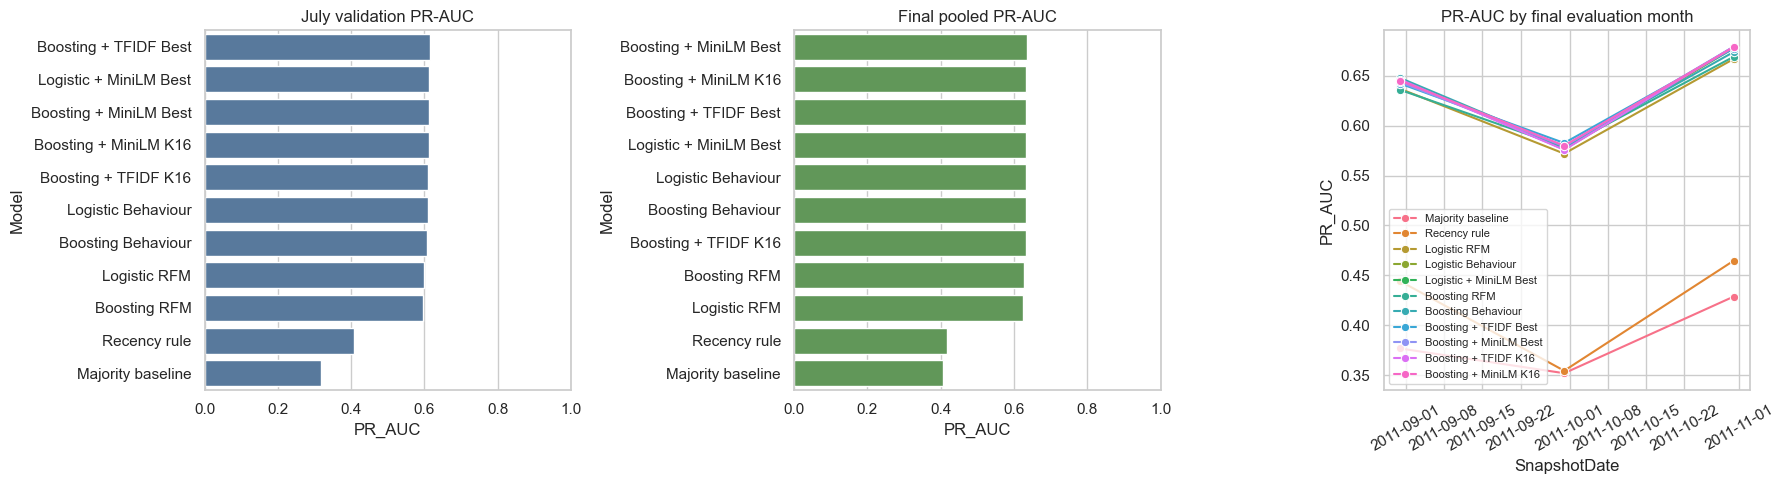

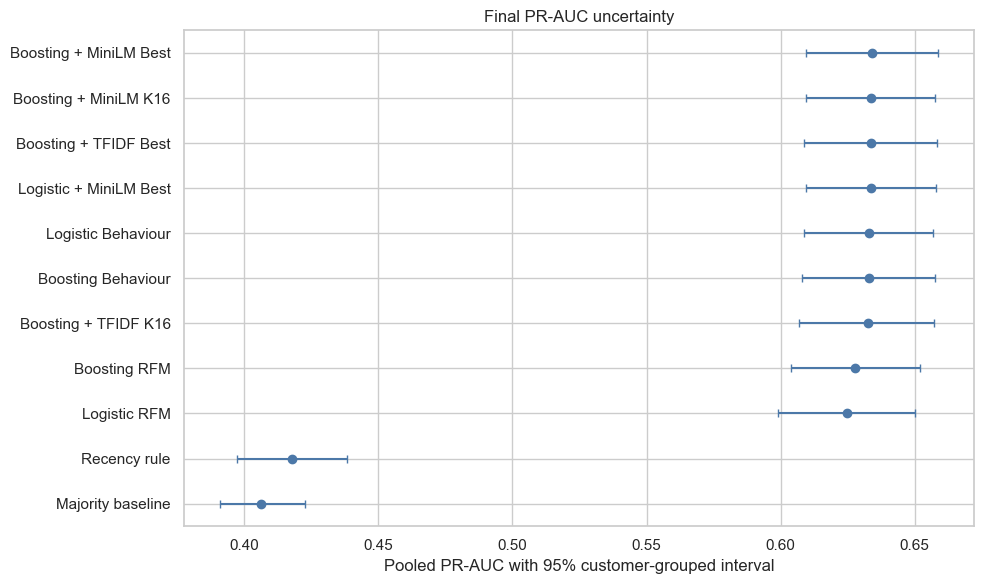

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(
    data=validation_results,
    y="Model",
    x="PR_AUC",
    color="#4C78A8",
    ax=axes[0],
)
axes[0].set_title("July validation PR-AUC")
axes[0].set_xlim(0, 1)
sns.barplot(
    data=pooled_results,
    y="Model",
    x="PR_AUC",
    color="#59A14F",
    ax=axes[1],
)
axes[1].set_title("Final pooled PR-AUC")
axes[1].set_xlim(0, 1)
sns.lineplot(
    data=rolling_results,
    x="SnapshotDate",
    y="PR_AUC",
    hue="Model",
    marker="o",
    ax=axes[2],
)
axes[2].set_title("PR-AUC by final evaluation month")
axes[2].tick_params(axis="x", rotation=30)
axes[2].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 6))
ordered = metric_uncertainty.sort_values("PR_AUC")
y = np.arange(len(ordered))
errors = np.vstack(
    [
        ordered["PR_AUC"] - ordered["PR_AUC_Low"],
        ordered["PR_AUC_High"] - ordered["PR_AUC"],
    ]
)
plt.errorbar(
    ordered["PR_AUC"],
    y,
    xerr=errors,
    fmt="o",
    color="#4C78A8",
    capsize=3,
)
plt.yticks(y, ordered["Model"])
plt.xlabel("Pooled PR-AUC with 95% customer-grouped interval")
plt.title("Final PR-AUC uncertainty")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metric_uncertainty.png", dpi=180, bbox_inches="tight")
plt.show()

## Model interpretation and error analysis
Permutation importance measures the decrease in October PR-AUC after shuffling one feature. It describes predictive dependence, not causality.

### Permutation importance: Boosting + TFIDF Best

,Feature,ImportanceMean,ImportanceStd
7,ActivePurchaseDays,0.145159,0.014324
1,LogFrequency90D,0.008714,0.003880
0,RecencyDays,0.004969,0.002532
2,LogMonetary90D,0.004090,0.001707
3,LogTotalUnits90D,0.002620,0.001884
23,TFIDFBestCluster01Share,0.002431,0.000665
43,TFIDFBestDiversity,0.001735,0.001001
12,HistorySpanDays90D,0.001695,0.002014
31,TFIDFBestCluster09Share,0.001488,0.000826
22,TFIDFBestCluster00Share,0.001473,0.000965


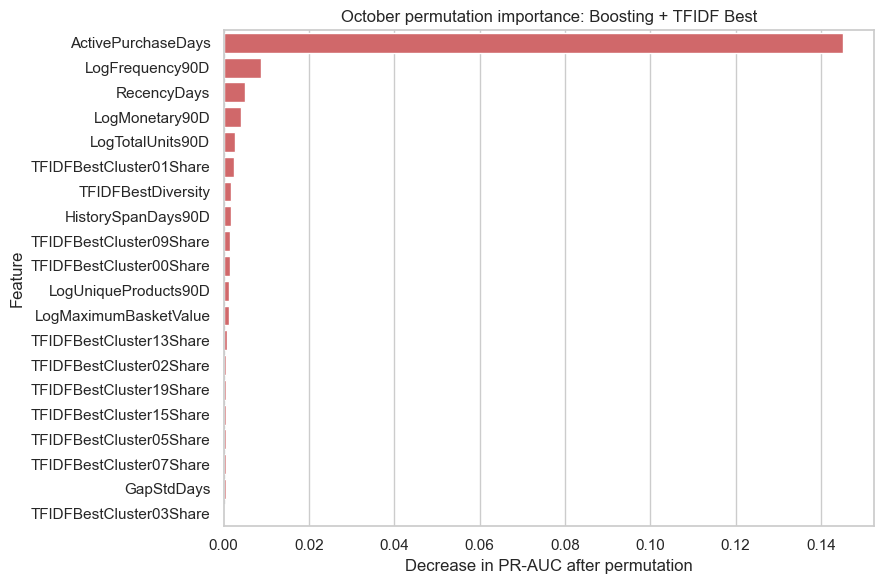

In [24]:
# Interpretation follows the July-selected learned model; the test set does not choose it.
INTERPRETED_MODEL = SELECTED_LEARNED_MODEL
best_features = model_specs[INTERPRETED_MODEL][1]
october_date = TEST_DATES[-1]
october = model_data.loc[model_data['SnapshotDate'].eq(october_date)].copy()
best_october_fit = final_fitted_models[(INTERPRETED_MODEL, october_date)]

perm = permutation_importance(
    best_october_fit, october[best_features], october[TARGET],
    scoring='average_precision', n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1
)
importance = (pd.DataFrame({'Feature': best_features, 'ImportanceMean': perm.importances_mean,
                            'ImportanceStd': perm.importances_std})
              .sort_values('ImportanceMean', ascending=False).head(20))
display(Markdown(f'### Permutation importance: {INTERPRETED_MODEL}'))
display(importance)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, y='Feature', x='ImportanceMean', color='#E15759')
plt.title(f'October permutation importance: {INTERPRETED_MODEL}')
plt.xlabel('Decrease in PR-AUC after permutation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'permutation_importance.png', dpi=180, bbox_inches='tight')
plt.show()
importance.to_csv(OUTPUT_DIR / 'permutation_importance.csv', index=False)

In [25]:
best_predictions = predictions.loc[predictions['Model'].eq(INTERPRETED_MODEL)].copy()
best_predictions['ErrorType'] = np.select(
    [(best_predictions['Actual'].eq(1) & best_predictions['Prediction'].eq(1)),
     (best_predictions['Actual'].eq(0) & best_predictions['Prediction'].eq(0)),
     (best_predictions['Actual'].eq(0) & best_predictions['Prediction'].eq(1)),
     (best_predictions['Actual'].eq(1) & best_predictions['Prediction'].eq(0))],
    ['True positive','True negative','False positive','False negative'], default='Unknown')

error_features = model_data[['SnapshotDate','CustomerID','RecencyDays','Frequency90D','Monetary90D',
                             'UniqueProducts90D','CancellationRate']].copy()
error_detail = best_predictions.merge(error_features, on=['SnapshotDate','CustomerID'], how='left')
error_summary = error_detail.groupby('ErrorType').agg(
    Customers=('CustomerID','size'),
    MedianRecency=('RecencyDays','median'),
    MedianFrequency=('Frequency90D','median'),
    MedianSpend=('Monetary90D','median'),
    MedianUniqueProducts=('UniqueProducts90D','median'),
    MedianCancellationRate=('CancellationRate','median')
).reset_index()
display(error_summary.round(2))
error_summary.to_csv(OUTPUT_DIR / 'error_analysis_summary.csv', index=False)

,ErrorType,Customers,MedianRecency,MedianFrequency,MedianSpend,MedianUniqueProducts,MedianCancellationRate
0,False negative,1254,36.51,1.0,334.42,20.0,0.0
1,False positive,831,22.46,2.0,799.15,36.0,0.0
2,True negative,3157,33.36,1.0,305.28,17.0,0.0
3,True positive,1276,17.39,3.0,1084.90,47.0,0.0


## Evidence-based conclusions

The ablation compares feature stages within the same model family. Paired intervals compare models on the same customer-grouped bootstrap samples. An interval that includes zero means the test data do not distinguish the two models.

In [26]:
result_lookup = pooled_results.set_index("Model")
selected_final = result_lookup.loc[SELECTED_MODEL]
posthoc_best = pooled_results.iloc[0]
monthly_best = rolling_results.loc[
    rolling_results.groupby("SnapshotDate")["PR_AUC"].idxmax(),
    ["SnapshotDate", "Model", "PR_AUC"],
]

ablation_pairs = [
    (
        "Logistic regression",
        "Logistic RFM",
        "Logistic Behaviour",
        "Logistic + MiniLM Best",
    ),
    (
        "Gradient boosting",
        "Boosting RFM",
        "Boosting Behaviour",
        "Boosting + MiniLM Best",
    ),
]
ablation_rows = []
for family, rfm_name, behaviour_name, minilm_name in ablation_pairs:
    rfm_pr = result_lookup.loc[rfm_name, "PR_AUC"]
    behaviour_pr = result_lookup.loc[behaviour_name, "PR_AUC"]
    minilm_pr = result_lookup.loc[minilm_name, "PR_AUC"]
    ablation_rows.append(
        {
            "ModelFamily": family,
            "RFM_PR_AUC": rfm_pr,
            "Behaviour_PR_AUC": behaviour_pr,
            "BehaviourGain": behaviour_pr - rfm_pr,
            "MiniLM_PR_AUC": minilm_pr,
            "MiniLMGain": minilm_pr - behaviour_pr,
        }
    )
ablation_summary = pd.DataFrame(ablation_rows)
tfidf_gain = (
    result_lookup.loc["Boosting + TFIDF Best", "PR_AUC"]
    - result_lookup.loc["Boosting Behaviour", "PR_AUC"]
)
ablation_summary.to_csv(OUTPUT_DIR / "ablation_summary.csv", index=False)

display(Markdown("### Feature ablation within each model family"))
display(
    ablation_summary.style.format(
        {
            "RFM_PR_AUC": "{:.3f}",
            "Behaviour_PR_AUC": "{:.3f}",
            "BehaviourGain": "{:+.3f}",
            "MiniLM_PR_AUC": "{:.3f}",
            "MiniLMGain": "{:+.3f}",
        }
    )
)

selected_interval = metric_uncertainty.set_index("Model").loc[SELECTED_MODEL]
print(
    f"Numerically highest July model: {SELECTED_MODEL}. "
    f"Final PR-AUC {selected_interval['PR_AUC']:.3f} "
    f"(95% interval {selected_interval['PR_AUC_Low']:.3f} to "
    f"{selected_interval['PR_AUC_High']:.3f}); "
    f"lift@20%={selected_final['LiftAt20']:.2f}."
)
print(
    f"The highest post-hoc final PR-AUC was {posthoc_best['Model']} "
    f"({posthoc_best['PR_AUC']:.3f}); this does not replace July selection."
)

for row in paired_model_differences.itertuples(index=False):
    conclusion = (
        "distinguishable"
        if row.ExcludesZero
        else "not distinguishable at the pooled test level"
    )
    print(
        f"{row.ModelA} minus {row.ModelB}: "
        f"{row.GainAminusB:+.3f} PR-AUC "
        f"(95% interval {row.GainLow:+.3f} to {row.GainHigh:+.3f}); "
        f"{conclusion}."
    )

print(
    f"TF-IDF best-K minus behavioural boosting: {tfidf_gain:+.3f} PR-AUC. "
    "Interpret this value with the paired interval above."
)
print(f"Monthly macro PR-AUC table: {OUTPUT_DIR / 'monthly_macro_pr_auc.csv'}")
display(Markdown("### Best model in each test month"))
display(monthly_best)

### Feature ablation within each model family

,ModelFamily,RFM_PR_AUC,Behaviour_PR_AUC,BehaviourGain,MiniLM_PR_AUC,MiniLMGain
0,Logistic regression,0.625,0.633,+0.008,0.634,+0.001
1,Gradient boosting,0.628,0.633,+0.005,0.634,+0.001


Numerically highest July model: Boosting + TFIDF Best. Final PR-AUC 0.634 (95% interval 0.609 to 0.658); lift@20%=1.77.
The highest post-hoc final PR-AUC was Boosting + MiniLM Best (0.634); this does not replace July selection.
Logistic Behaviour minus Logistic RFM: +0.008 PR-AUC (95% interval +0.003 to +0.013); distinguishable.
Logistic + MiniLM Best minus Logistic Behaviour: +0.001 PR-AUC (95% interval -0.002 to +0.003); not distinguishable at the pooled test level.
Boosting Behaviour minus Boosting RFM: +0.005 PR-AUC (95% interval -0.001 to +0.011); not distinguishable at the pooled test level.
Boosting + TFIDF Best minus Boosting Behaviour: +0.001 PR-AUC (95% interval -0.003 to +0.005); not distinguishable at the pooled test level.
Boosting + MiniLM Best minus Boosting Behaviour: +0.001 PR-AUC (95% interval -0.003 to +0.005); not distinguishable at the pooled test level.
Boosting + TFIDF K16 minus Boosting Behaviour: -0.000 PR-AUC (95% interval -0.004 to +0.004); not distinguishabl

### Best model in each test month

,SnapshotDate,Model,PR_AUC
6,2011-08-31,Boosting Behaviour,0.64771
18,2011-09-30,Boosting + TFIDF Best,0.58264
30,2011-10-31,Boosting + MiniLM Best,0.67909


## Limitations and responsible interpretation

1. This is observational transaction data. Prediction does not prove that a retention action causes a repeat purchase.
2. Customers without identifiers cannot enter customer-level modelling, so conclusions apply only to identified customers.
3. Merchandise features exclude postage, carriage, adjustments, fees, and vouchers. The revenue audit reports the excluded amount.
4. The retailer includes wholesalers. Large baskets and repeat patterns may not represent a typical consumer retailer.
5. MiniLM is a general-purpose encoder. Product clusters require inspection, and low silhouette scores limit claims about semantic separation.
6. The final evaluation covers three monthly snapshots. Reporting each month prevents a pooled average from hiding instability.
7. Repeated customers appear across snapshots. Customer-grouped bootstrap intervals preserve this dependence, but only three test months contribute to the final test result.
8. Exact duplicate removal is documented and tested as a sensitivity check. It changes revenue slightly and changes no measured monthly target labels.
9. The 95% intervals describe sampling variation across customers. They do not cover all uncertainty from choosing one retailer, one year, or one model family.

In [27]:
output_manifest = pd.DataFrame(
    {
        "File": sorted(
            path.name for path in OUTPUT_DIR.iterdir() if path.is_file()
        )
    }
)
display(output_manifest)
print("Notebook completed successfully.")

,File
0,ablation_summary.csv
1,boosting_tuning.csv
2,cleaning_audit.csv
3,cluster_matched_k_quality.csv
4,cluster_quality.csv
5,customer_snapshot_features.csv
6,eda_country_activity.csv
7,eda_customer_concentration.csv
8,eda_customer_concentration.png
9,eda_data_quality.csv


Notebook completed successfully.
